In [1]:
import os 
import sys 
import time

import cv2 
import numpy as np 
import pandas as pd

import seaborn as sns 
import matplotlib.pylab as plt 
from sklearn.model_selection import train_test_split 
from sklearn.metrics import confusion_matrix



from tensorflow.keras.models import Sequential , load_model
from tensorflow.keras.utils import plot_model
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.io import read_file
from tensorflow.image import decode_jpeg, resize 
from tensorflow.data import Dataset
from tensorflow.data import AUTOTUNE
from tensorflow.keras.layers import (
    Conv2D, 
    MaxPool2D, 
    Dropout,
    Flatten, 
    Dense, 
    Input, 
)
from tensorflow.keras.optimizers import Adam


sys.path.append(os.path.abspath('..'))

from src.config.config import VALID_EXTENSIONS, IMG_SIZE, SEED , BATCH_SIZE, ROOT, EPOCHS, LEARNING_RATE

I0000 00:00:1792408979.623841  552313 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792408979.624193  552313 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792408979.648977  552313 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792408980.373297  552313 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [2]:
def load_image(path , label) : 
    try : 

        image = read_file(path)
        image = decode_jpeg(image, channels=3)
        image = resize(image, IMG_SIZE)
        return image, label

    except Exception as e : 
        print(f"Error loading image {path} : {e}")
        return None , label

def make_data(paths, labels) : 
    ds = Dataset.from_tensor_slices((paths, labels))

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)

    ds = ds.batch(BATCH_SIZE)

    return ds.prefetch(AUTOTUNE) 
    


In [3]:
classes = sorted (
    p.name for p in ROOT.iterdir() if p.is_dir()
)
classes

['glioma', 'meningioma', 'notumor', 'pituitary']

In [4]:
class_to_id = {
    name: i for i, name in enumerate(classes)
}
class_to_id

{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}

In [5]:
paths, labels = [], []

for class_name in classes : 
    for file in (ROOT / class_name).rglob('*') : 
        if file.is_file() and file.suffix.lower() in VALID_EXTENSIONS : 
            paths.append(str(file))
            labels.append(class_to_id[class_name])

In [6]:
print("Classes:", class_to_id)
print("Images:", len(paths))

Classes: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Images: 7023


In [7]:
# count = 0 

# labels = [ ]
# images = [ ]

# for root, dirs, files in os.walk('../data') : 

#     for file in files : 

#         file_path = os.path.join(root, file)

#         if not file.lower().endswith(VALID_EXTENSIONS) : 
#             os.remove(file_path)
#             count += 1
#             continue 

#         try : 
#             img = cv2.imread(file_path )

#             img = cv2.resize(img, IMG_SIZE)

#             images.append(img)
#             labels.append(os.path.basename(root))
#         except cv2.error : 
#             os.remove(file_path)
#             count += 1
#             continue

# print("Nombre d'images :", len(images))
# print("Nombre de labels :", len(labels))``

In [8]:
# sns.countplot(x=labels, order=pd.Series(labels).value_counts().index , hue=labels) 
# plt.title("Distribution des classes")
# plt.xlabel("Classes")

# plt.show()

In [9]:
# fig , axes = plt.subplots(4, 3, figsize=(12, 12))

# # i want get the first 3 from evry class and plot them ?  can you help me with that ? 

# for i, label in enumerate(pd.Series(labels).value_counts().index) :
#     label_images = [images[j] for j in range(len(labels)) if labels[j] == label ] 

#     for j in range(3) : 
#         axes[i, j].imshow(label_images[j])
#         axes[i, j].set_title(label)
#         axes[i, j].axis('off')


In [10]:
X_train, X_temp, Y_train, Y_temp = train_test_split(
    paths,
    labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

In [11]:
X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp,
    Y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=Y_temp
)

In [12]:
model = Sequential ([
    Input(shape=(*IMG_SIZE, 3)) ,
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPool2D((2, 2)) , 
    Conv2D(64 , (3, 3) , activation='relu'), 
    MaxPool2D((2, 2)) , 

    Flatten() , 

    Dense(128, activation='relu') ,  

    Dropout(0.5) , 
    
    Dense(len(np.unique(labels)), activation='softmax')
])

E0000 00:00:1792408980.743423  552313 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [13]:
model.compile(
    loss='sparse_categorical_crossentropy', 
    optimizer=Adam(learning_rate=LEARNING_RATE),
    metrics=['accuracy']
)


In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 110, 110, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 55, 55, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 193600)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    24,780,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,800,836 (94.61 MB)

 Trainable params: 24,800,836 (94.61 MB)

 Non-trainable params: 0 (0.00 B)

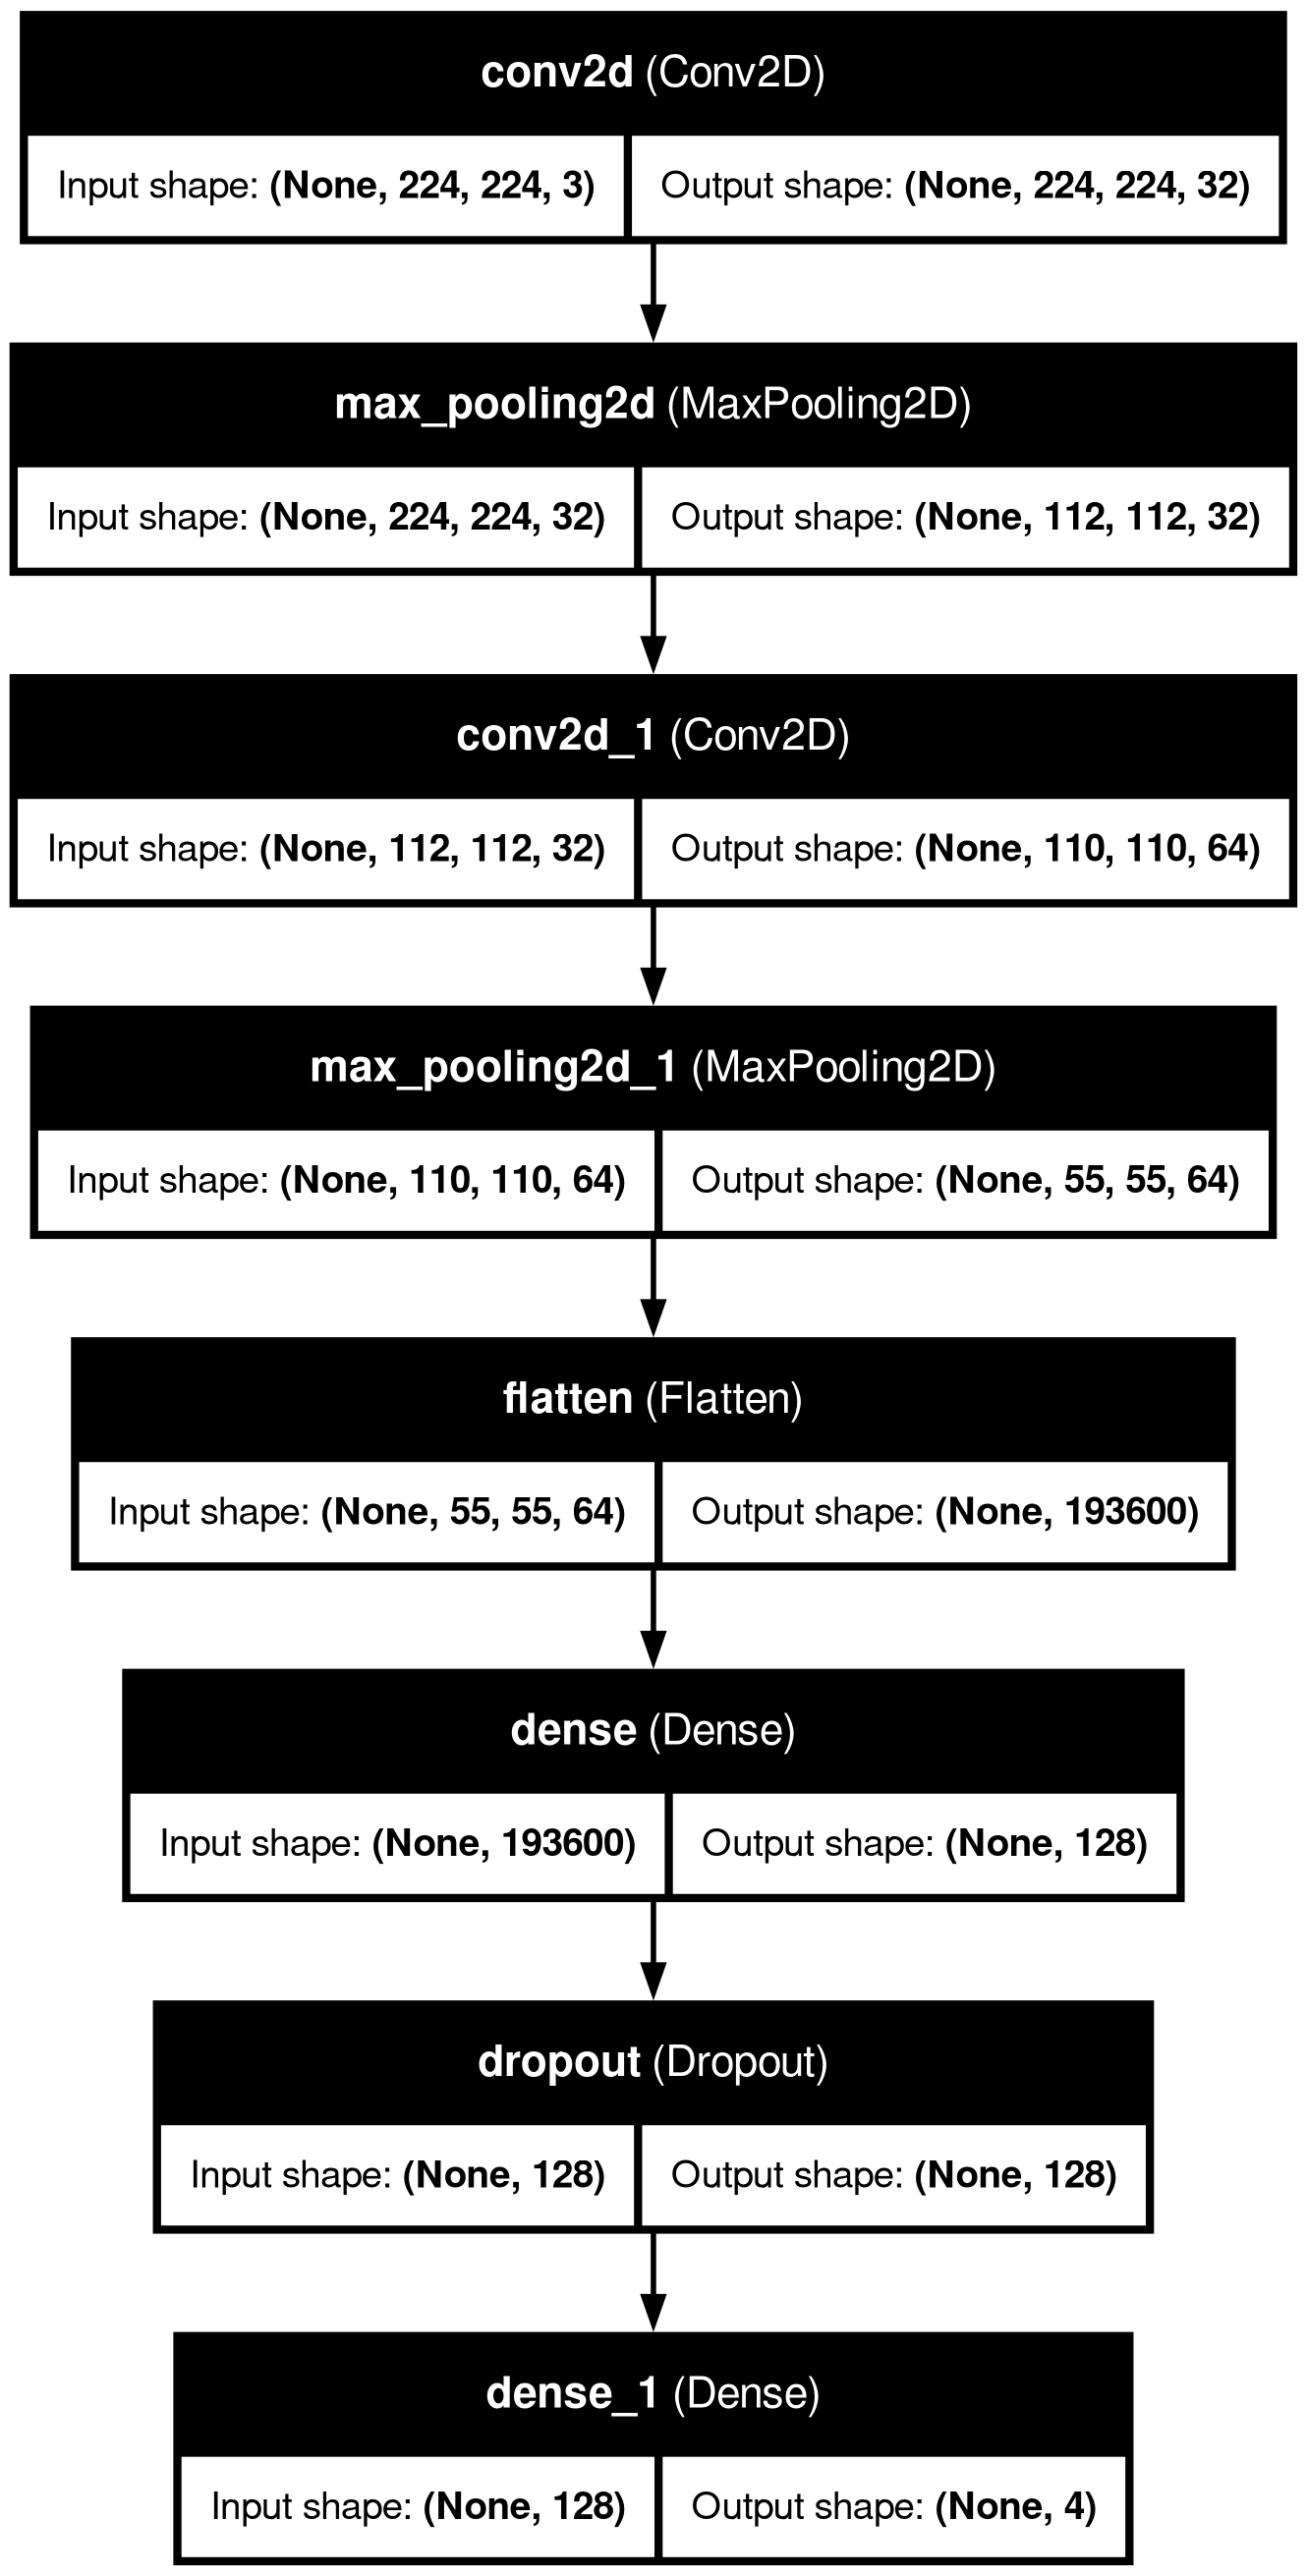

In [15]:
plot_model(model, show_shapes=True, show_layer_names=True  )

In [16]:
checkpoint = ModelCheckpoint(
    filepath="models/best_model.keras",
    monitor="val_recall",
    save_best_only=True,
    mode="max",
    verbose=1
)

In [17]:
start_time = time.time()

history = model.fit(
    make_data(X_train, Y_train), 
    validation_data=make_data(X_val, Y_val),
    epochs=EPOCHS,
    callbacks=[checkpoint]
)
end_time = time.time()
training_duration = end_time - start_time

Epoch 1/20


/home/fangyuan/Projects/BrainScan/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 739ms/step - accuracy: 0.7168 - loss: 42.8368

/home/fangyuan/Projects/BrainScan/.venv/lib/python3.14/site-packages/keras/src/callbacks/model_checkpoint.py:330: UserWarning: Can save best model only with val_recall available.
  if self._should_save_model(epoch, batch, logs, filepath):



Epoch 1: finished saving model to models/best_model.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 120s 774ms/step - accuracy: 0.7168 - loss: 42.8368 - val_accuracy: 0.8794 - val_loss: 0.4056
Epoch 2/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 718ms/step - accuracy: 0.8741 - loss: 0.4060
Epoch 2: finished saving model to models/best_model.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 116s 751ms/step - accuracy: 0.8741 - loss: 0.4060 - val_accuracy: 0.8955 - val_loss: 0.3429
Epoch 3/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 776ms/step - accuracy: 0.9162 - loss: 0.2370
Epoch 3: finished saving model to models/best_model.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 125s 810ms/step - accuracy: 0.9162 - loss: 0.2370 - val_accuracy: 0.9126 - val_loss: 0.2894
Epoch 4/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 875ms/step - accuracy: 0.9447 - loss: 0.1990
Epoch 4: finished saving model to models/best_model.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 140s 909ms/step - accuracy: 0.9447 - loss: 0.1990 - val_accuracy: 0.9202 - val_loss: 0.2902
Epoch 5/20
154/154

In [18]:
print(f"Durée de l'entraînement : {training_duration:.2f} secondes")
print( history.history["accuracy"][-1])

Durée de l'entraînement : 2446.59 secondes
0.9798616766929626


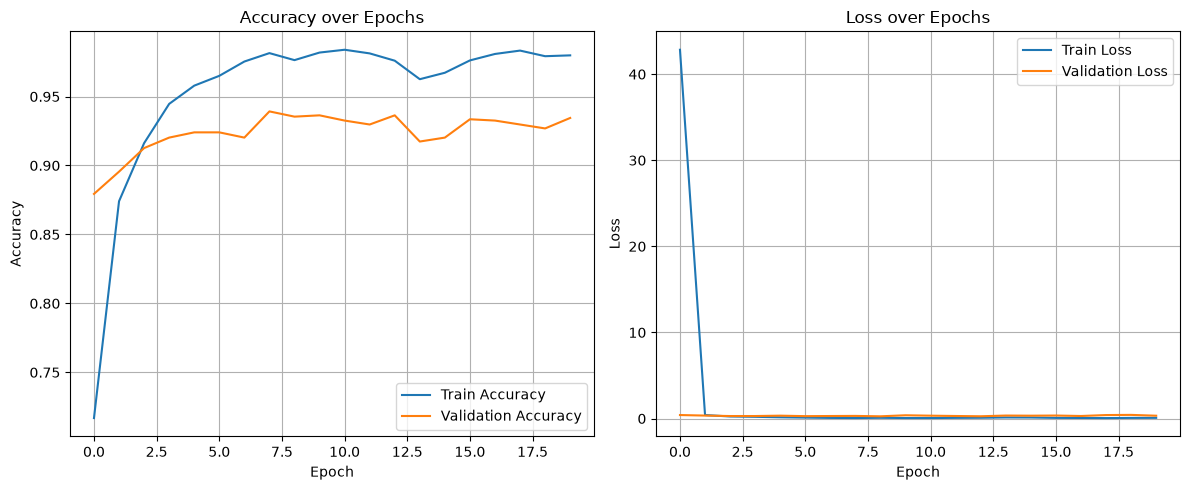

In [21]:
fig , axes = plt.subplots(1, 2, figsize=(12, 5))

# Accuracy
axes[0].plot(history.history['accuracy'], label='Train Accuracy')
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy')
axes[0].set_title('Accuracy over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(history.history['loss'], label='Train Loss')
axes[1].plot(history.history['val_loss'], label='Validation Loss')
axes[1].set_title('Loss over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [29]:
best_model = load_model("/home/fangyuan/Projects/BrainScan/models/best_model.keras")

test_ds = make_data(X_test, Y_test)

y_pred_proba = best_model.predict(test_ds)

y_true = np.array(Y_test).astype(int).reshape(-1)
y_pred = np.argmax(y_pred_proba, axis=1)



33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 133ms/step


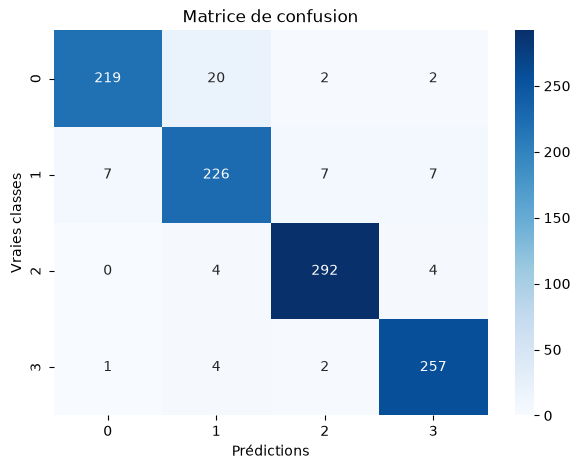

In [30]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Prédictions")
plt.ylabel("Vraies classes")
plt.title("Matrice de confusion")
plt.show()